# 01 - Graph from the Q-matrix

The Q-matrix says which skills each item needs. Rule: item A is a prerequisite of item B if the skills of A are a subset of the skills of B.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import project_paths as paths

from kst.q_matrix import load_q_matrix, skills_of_item, q_prerequisite_pairs
from kst.graph_tools import graph_from_pairs, draw_graph

## Q-matrix (rows are items, columns are skills)

In [3]:
q_matrix = load_q_matrix(paths.TATSUOKA_Q_MATRIX)
pd.DataFrame(q_matrix, index=range(1, 21), columns=range(1, 9))

,1,2,3,4,5,6,7,8
1,0,0,0,1,0,1,1,0
2,0,0,0,1,0,0,1,0
3,0,0,0,1,0,0,1,0
4,0,1,1,0,1,0,1,0
5,0,1,0,1,0,0,1,1
6,0,0,0,0,0,0,1,0
7,1,1,0,0,0,0,1,0
8,0,0,0,0,0,0,1,0
9,0,1,0,0,0,0,0,0
10,0,1,0,0,1,0,1,1


## Example: skills of two items

In [4]:
print("item 2 needs skills", skills_of_item(q_matrix, 2))
print("item 5 needs skills", skills_of_item(q_matrix, 5))

item 2 needs skills {4, 7}
item 5 needs skills {8, 2, 4, 7}


## All prerequisite pairs

`(a, b)` means: a is a prerequisite of b.

In [5]:
q_pairs = q_prerequisite_pairs(q_matrix)
print(len(q_pairs), "pairs")
sorted(q_pairs)[:10]

101 pairs


[(2, 1),
 (2, 3),
 (2, 5),
 (2, 13),
 (3, 1),
 (3, 2),
 (3, 5),
 (3, 13),
 (4, 19),
 (4, 20)]

## Drawing

Items with identical skills are shown together as one box. Only direct arrows are drawn (no shortcuts).

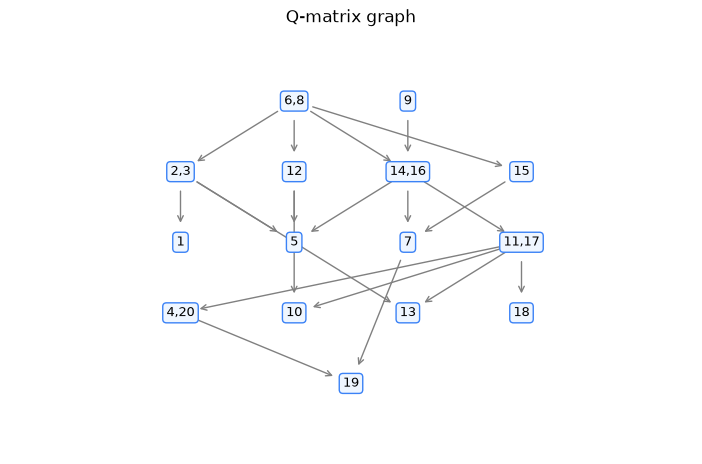

In [6]:
groups, cover_pairs = graph_from_pairs(q_pairs, list(range(1, 21)))
draw_graph(groups, cover_pairs, "Q-matrix graph")